In [ ]:
import pandas as pd
import numpy as np
import requests

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("All libraries imported successfully!")


Pandas version: 2.2.3
NumPy version: 2.4.6
All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving .gitkeep to .gitkeep
Saving genres.csv to genres.csv
Saving ownership-concentration.csv to ownership-concentration.csv
Saving price-tiers.csv to price-tiers.csv
Saving pricing-by-year.csv to pricing-by-year.csv
Saving review-by-genre.csv to review-by-genre.csv


In [ ]:
import pandas as pd
import io

# Store all five datasets in a dictionary
datasets = {}

for filename, file_content in uploaded.items():
    # Skip empty files like .gitkeep and only process CSV files
    if not filename.endswith('.csv') or len(file_content) == 0:
        continue

    df = pd.read_csv(io.BytesIO(file_content))

    datasets[filename] = df

    print(f"\nDataset: {filename}")
    print("Rows and columns:", df.shape)
    print("Column names:", df.columns.tolist())


Dataset: genres.csv
Rows and columns: (20, 2)
Column names: ['genre', 'games']

Dataset: ownership-concentration.csv
Rows and columns: (4, 2)
Column names: ['top_slice', 'owner_share']

Dataset: price-tiers.csv
Rows and columns: (6, 2)
Column names: ['price_tier', 'games']

Dataset: pricing-by-year.csv
Rows and columns: (21, 5)
Column names: ['release_year', 'titles', 'free_share', 'median_price_usd', 'mean_price_usd']

Dataset: review-by-genre.csv
Rows and columns: (19, 4)
Column names: ['genre', 'titles', 'median_review_score', 'free_share']


In [ ]:
for filename, df in datasets.items():

    print("\n" + "=" * 60)
    print("DATASET:", filename)
    print("=" * 60)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nData types:")
    print(df.dtypes)


DATASET: genres.csv

First 5 rows:


,genre,games
0,Indie,5940
1,Action,4797
2,Adventure,4091
3,Casual,2534
4,RPG,2523



Missing values:
genre    0
games    0
dtype: int64

Duplicate rows: 0

Data types:
genre    object
games     int64
dtype: object

DATASET: ownership-concentration.csv

First 5 rows:


,top_slice,owner_share
0,top_1pct,0.3275
1,top_5pct,0.5355
2,top_10pct,0.6461
3,top_25pct,0.8050



Missing values:
top_slice      0
owner_share    0
dtype: int64

Duplicate rows: 0

Data types:
top_slice       object
owner_share    float64
dtype: object

DATASET: price-tiers.csv

First 5 rows:


,price_tier,games
0,under5,3528
1,5to15,2627
2,free,2007
3,15to30,1429
4,30to60,382



Missing values:
price_tier    0
games         0
dtype: int64

Duplicate rows: 0

Data types:
price_tier    object
games          int64
dtype: object

DATASET: pricing-by-year.csv

First 5 rows:


,release_year,titles,free_share,median_price_usd,mean_price_usd
0,2006,35,0.029,4.99,6.79
1,2007,74,0.189,2.99,5.36
2,2008,89,0.191,3.99,7.06
3,2009,153,0.137,4.99,7.13
4,2010,113,0.124,4.99,6.94



Missing values:
release_year        0
titles              0
free_share          0
median_price_usd    0
mean_price_usd      0
dtype: int64

Duplicate rows: 0

Data types:
release_year          int64
titles                int64
free_share          float64
median_price_usd    float64
mean_price_usd      float64
dtype: object

DATASET: review-by-genre.csv

First 5 rows:


,genre,titles,median_review_score,free_share
0,Indie,5940,1.000,0.183
1,Action,4797,0.818,0.196
2,Adventure,4091,0.840,0.156
3,Casual,2534,1.000,0.230
4,RPG,2523,0.816,0.189



Missing values:
genre                  0
titles                 0
median_review_score    0
free_share             0
dtype: int64

Duplicate rows: 0

Data types:
genre                   object
titles                   int64
median_review_score    float64
free_share             float64
dtype: object


In [ ]:

# ================================================
# STEP 4: DATA VALIDATION
# Project 1: Steam Gaming Market Analysis
# ================================================

# 1. Check unique identifiers and data quality

key_columns = {
    "genres.csv": "genre",
    "ownership-concentration.csv": "top_slice",
    "price-tiers.csv": "price_tier",
    "pricing-by-year.csv": "release_year",
    "review-by-genre.csv": "genre"
}

print("DATA QUALITY VALIDATION")
print("=" * 60)

for filename, df in datasets.items():

    key = key_columns[filename]

    print(f"\nDataset: {filename}")
    print("-" * 40)

    print("Missing values:", df.isnull().sum().sum())

    print("Duplicate rows:", df.duplicated().sum())

    print(f"Duplicate {key} values:", df[key].duplicated().sum())

    print("Total records:", len(df))


# 2. Check percentage and ratio columns

print("\n\nPERCENTAGE VALIDATION")
print("=" * 60)

percentage_columns = {
    "ownership-concentration.csv": ["owner_share"],
    "pricing-by-year.csv": ["free_share"],
    "review-by-genre.csv": [
        "median_review_score",
        "free_share"
    ]
}

for filename, columns in percentage_columns.items():

    df = datasets[filename]

    print(f"\n{filename}")

    for column in columns:

        print(
            column,
            "| Minimum:", df[column].min(),
            "| Maximum:", df[column].max()
        )

        if not df[column].between(0, 1).all():
            print("WARNING: Values outside 0–1 range!")


# 3. Check whether ownership concentration increases

ownership = datasets["ownership-concentration.csv"]

print("\n\nOWNERSHIP VALIDATION")
print("=" * 60)

print(ownership)

is_increasing = ownership["owner_share"].is_monotonic_increasing

print("\nOwnership shares increase:", is_increasing)


# 4. Compare genre names across the two datasets

genres = set(datasets["genres.csv"]["genre"])

review_genres = set(
    datasets["review-by-genre.csv"]["genre"]
)

print("\n\nGENRE COMPARISON")
print("=" * 60)

print("Genres in genre dataset:", len(genres))

print("Genres in review dataset:", len(review_genres))

print("Genres without review data:")
print(sorted(genres - review_genres))

print("Unexpected review-only genres:")
print(sorted(review_genres - genres))


# 5. Check total game counts in relevant datasets

print("\n\nDATASET TOTALS")
print("=" * 60)

price_total = datasets["price-tiers.csv"]["games"].sum()

year_total = datasets["pricing-by-year.csv"]["titles"].sum()

genre_total = datasets["genres.csv"]["games"].sum()

review_genre_total = (
    datasets["review-by-genre.csv"]["titles"].sum()
)

print("Total games across price tiers:", price_total)

print("Total titles across release years:", year_total)

print("Total genre assignments:", genre_total)

print("Total genre titles in review table:", review_genre_total)


# 6. Inspect the most recent release years

print("\n\nRECENT RELEASE YEAR DATA")
print("=" * 60)

display(
    datasets["pricing-by-year.csv"].tail(6)
)

print("\nVALIDATION COMPLETE")


DATA QUALITY VALIDATION

Dataset: genres.csv
----------------------------------------
Missing values: 0
Duplicate rows: 0
Duplicate genre values: 0
Total records: 20

Dataset: ownership-concentration.csv
----------------------------------------
Missing values: 0
Duplicate rows: 0
Duplicate top_slice values: 0
Total records: 4

Dataset: price-tiers.csv
----------------------------------------
Missing values: 0
Duplicate rows: 0
Duplicate price_tier values: 0
Total records: 6

Dataset: pricing-by-year.csv
----------------------------------------
Missing values: 0
Duplicate rows: 0
Duplicate release_year values: 0
Total records: 21

Dataset: review-by-genre.csv
----------------------------------------
Missing values: 0
Duplicate rows: 0
Duplicate genre values: 0
Total records: 19


PERCENTAGE VALIDATION

ownership-concentration.csv
owner_share | Minimum: 0.3275 | Maximum: 0.805

pricing-by-year.csv
free_share | Minimum: 0.029 | Maximum: 0.312

review-by-genre.csv
median_review_score | Min

,release_year,titles,free_share,median_price_usd,mean_price_usd
15,2021,847,0.201,6.99,10.85
16,2022,692,0.121,8.99,13.49
17,2023,721,0.096,8.99,13.30
18,2024,715,0.070,9.99,14.51
19,2025,306,0.033,13.26,16.69
20,2026,58,0.069,17.99,18.20



VALIDATION COMPLETE


In [ ]:

# Display all price tiers
display(datasets["price-tiers.csv"])

# Display all genres and their game counts
display(datasets["genres.csv"])


,price_tier,games
0,under5,3528
1,5to15,2627
2,free,2007
3,15to30,1429
4,30to60,382
5,over60,27


,genre,games
0,Indie,5940
1,Action,4797
2,Adventure,4091
3,Casual,2534
4,RPG,2523
5,Strategy,2502
6,Simulation,2320
7,Free To Play,1307
8,Massively Multiplayer,574
9,Early Access,570


In [1]:

# ============================================
# STEP 5: CLEAN AND EXPORT STEAM DATASETS
# ============================================

import pandas as pd
import io
import os
import zipfile

from google.colab import files

# Upload the five original CSV files
uploaded = files.upload()

# Expected filenames
expected_files = [
    "genres.csv",
    "ownership-concentration.csv",
    "price-tiers.csv",
    "pricing-by-year.csv",
    "review-by-genre.csv"
]

# Check that all five files are uploaded
missing_files = [
    name for name in expected_files
    if name not in uploaded
]

if missing_files:
    raise ValueError(
        f"Missing files: {missing_files}"
    )

# Define expected numeric columns
numeric_columns = {
    "genres.csv": ["games"],

    "ownership-concentration.csv": [
        "owner_share"
    ],

    "price-tiers.csv": ["games"],

    "pricing-by-year.csv": [
        "release_year",
        "titles",
        "free_share",
        "median_price_usd",
        "mean_price_usd"
    ],

    "review-by-genre.csv": [
        "titles",
        "median_review_score",
        "free_share"
    ]
}

# Integer columns
integer_columns = {
    "genres.csv": ["games"],
    "price-tiers.csv": ["games"],
    "pricing-by-year.csv": [
        "release_year", "titles"
    ],
    "review-by-genre.csv": ["titles"]
}

# Create output folder in Colab
output_folder = "/content/steam_cleaned"

os.makedirs(output_folder, exist_ok=True)

cleaned_datasets = {}

# Clean each dataset
for filename in expected_files:

    print(f"\nProcessing: {filename}")

    df = pd.read_csv(
        io.BytesIO(uploaded[filename])
    )

    original_rows = len(df)

    # Standardise column names
    df.columns = [
        col.strip().lower()
        for col in df.columns
    ]

    # Remove unwanted spaces from text fields
    for col in df.select_dtypes(
        include=["object", "string"]
    ).columns:

        df[col] = df[col].str.strip()

    # Convert numeric columns
    for col in numeric_columns[filename]:

        df[col] = pd.to_numeric(
            df[col],
            errors="raise"
        )

    # Ensure integer columns are integers
    for col in integer_columns.get(filename, []):

        if not df[col].mod(1).eq(0).all():
            raise ValueError(
                f"Non-integer values found in {col}"
            )

        df[col] = df[col].astype("int64")

    # Validate percentages and ratios
    for col in [
        c for c in df.columns
        if c in [
            "owner_share",
            "free_share",
            "median_review_score"
        ]
    ]:

        if not df[col].between(0, 1).all():
            raise ValueError(
                f"Invalid ratio detected in {filename}: {col}"
            )

    # Preserve records: do not delete automatically
    if df.isnull().sum().sum() > 0:
        raise ValueError(
            f"Missing values detected in {filename}"
        )

    if df.duplicated().sum() > 0:
        raise ValueError(
            f"Duplicate rows detected in {filename}"
        )

    # Save cleaned CSV
    output_path = os.path.join(
        output_folder,
        filename
    )

    df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    cleaned_datasets[filename] = df

    print("Original rows:", original_rows)
    print("Cleaned rows:", len(df))
    print("Exported:", filename)

print("\nALL FIVE DATASETS EXPORTED SUCCESSFULLY!")

# Package the five files into one ZIP
zip_path = "/content/Steam_Cleaned_Datasets.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in expected_files:

        zip_file.write(
            os.path.join(output_folder, filename),
            arcname=filename
        )

# Download ZIP
files.download(zip_path)


Saving genres.csv to genres.csv
Saving ownership-concentration.csv to ownership-concentration.csv
Saving price-tiers.csv to price-tiers.csv
Saving pricing-by-year.csv to pricing-by-year.csv
Saving review-by-genre.csv to review-by-genre.csv

Processing: genres.csv
Original rows: 20
Cleaned rows: 20
Exported: genres.csv

Processing: ownership-concentration.csv
Original rows: 4
Cleaned rows: 4
Exported: ownership-concentration.csv

Processing: price-tiers.csv
Original rows: 6
Cleaned rows: 6
Exported: price-tiers.csv

Processing: pricing-by-year.csv
Original rows: 21
Cleaned rows: 21
Exported: pricing-by-year.csv

Processing: review-by-genre.csv
Original rows: 19
Cleaned rows: 19
Exported: review-by-genre.csv

ALL FIVE DATASETS EXPORTED SUCCESSFULLY!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import pandas as pd
import io

# Find the uploaded CSV filename automatically
filename = next(
    name for name in uploaded
    if name.startswith("pricing-by-year")
    and name.endswith(".csv")
)

# Load the dataset
yearly = pd.read_csv(
    io.BytesIO(uploaded[filename])
)

# Inspect the data
print("Loaded file:", filename)
print("Dataset shape:", yearly.shape)

display(yearly.head())

Loaded file: pricing-by-year (1).csv
Dataset shape: (21, 5)


,release_year,titles,free_share,median_price_usd,mean_price_usd
0,2006,35,0.029,4.99,6.79
1,2007,74,0.189,2.99,5.36
2,2008,89,0.191,3.99,7.06
3,2009,153,0.137,4.99,7.13
4,2010,113,0.124,4.99,6.94


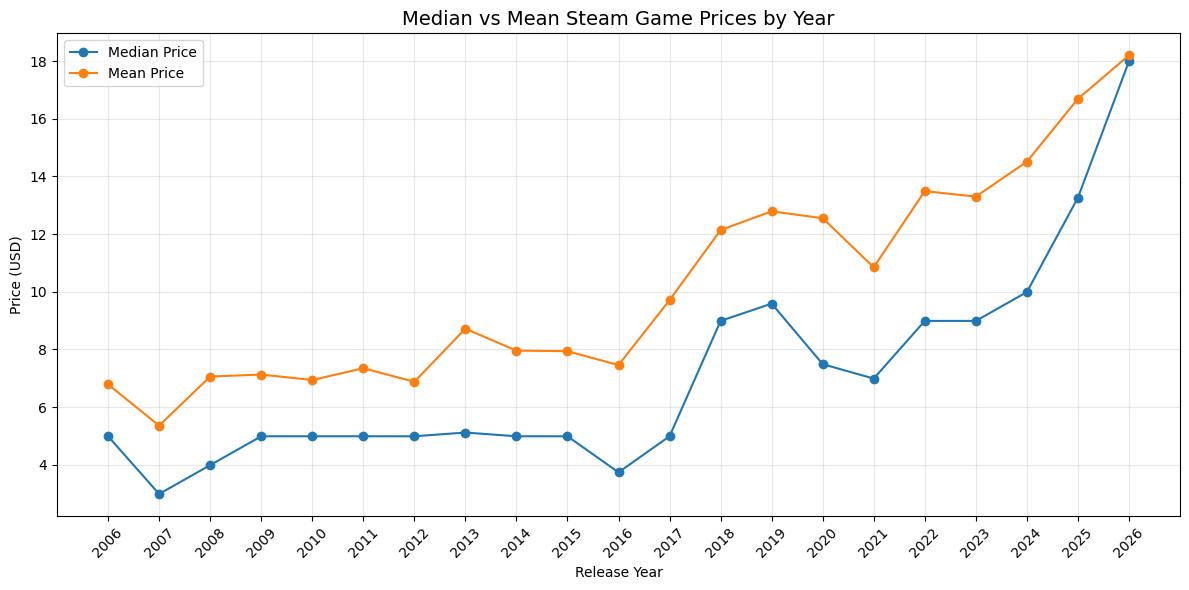

In [4]:

import matplotlib.pyplot as plt

# Create chart canvas
plt.figure(figsize=(12, 6))

# Median price line
plt.plot(
    yearly["release_year"],
    yearly["median_price_usd"],
    marker="o",
    label="Median Price"
)

# Mean price line
plt.plot(
    yearly["release_year"],
    yearly["mean_price_usd"],
    marker="o",
    label="Mean Price"
)

# Chart title and labels
plt.title(
    "Median vs Mean Steam Game Prices by Year",
    fontsize=14
)

plt.xlabel("Release Year")
plt.ylabel("Price (USD)")

# Formatting
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(yearly["release_year"], rotation=45)

plt.tight_layout()

# Save chart
plt.savefig(
    "pricing_trends.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()
